# 🛒 Market Basket Analysis using Data Mining
**Course:** Data Mining Lab (CSE-404) · Feni University · **Lab Report No. 01 – Labs 1 to 12**

This notebook contains all the code used in the lab report. Every lab is one section, run top to bottom:

| Lab | Topic | Lab | Topic |
|---|---|---|---|
| 1 | Python & Pandas basics | 7 | Naive Bayes classification |
| 2 | Preprocessing | 8 | SVM classification |
| 3 | Visualization & EDA | 9 | K-Means customer segmentation (RFM) |
| 4 | Apriori | 10 | Hierarchical clustering & DBSCAN |
| 5 | FP-Growth | 11 | Outliers & Random Forest |
| 6 | Decision Tree classification | 12 | End-to-end recommender + interactive dashboard |

**Dataset:** a *synthetic* grocery-store transaction file (6,000 baskets, 37 products, fixed random seed) created in Step 0, stored in `data/market_basket_transactions.csv` (if the file is missing, Step 0 regenerates a similar one). To use real data (e.g. the Kaggle *Groceries* dataset), save it as `data/market_basket_transactions.csv` with the columns `TransactionID, CustomerID, Date, Item, Quantity, UnitPrice` and skip Step 0.

**Run on Google Colab:** upload this notebook → *Runtime → Run all* (pandas, scikit-learn, scipy, mlxtend and ipywidgets are pre-installed).
Outputs shown for Labs 4, 5 and 12 appear after you run them (they need `mlxtend`).

## Step 0 · Dataset
Uses `data/market_basket_transactions.csv` (the synthetic grocery file used in the lab report). If the file is missing, a similar synthetic file is generated automatically.

In [ ]:
import os
import numpy as np, pandas as pd

PATH = "data/market_basket_transactions.csv"
os.makedirs("data", exist_ok=True)

if os.path.exists(PATH):
    print("Using the existing dataset:", PATH)
else:   # fallback: regenerate a synthetic dataset (numbers may differ slightly from the lab report)
    rng = np.random.default_rng(42)
    price = {"Milk":1.2,"Butter":2.5,"Cheese":4.0,"Yogurt":1.1,"Eggs":2.2,"Bread":1.5,"Buns":1.3,"Cake":6.0,
     "Bananas":0.9,"Apples":2.0,"Tomatoes":1.4,"Onions":0.8,"Potatoes":0.9,"Lettuce":1.2,
     "Chicken":6.5,"Beef":9.0,"Fish":7.5,"Rice":3.5,"Pasta":1.8,"Flour":1.6,"Sugar":1.3,"Cooking Oil":4.5,"Salt":0.6,"Lentils":2.4,
     "Tea":3.2,"Coffee":5.5,"Soda":1.5,"Juice":2.3,"Water":0.7,"Chips":1.4,"Biscuits":1.1,"Chocolate":2.0,
     "Soap":1.0,"Detergent":5.0,"Tissue":1.8,"Diapers":9.5,"Baby Food":3.0}
    items = list(price)
    missions = {
     "breakfast": (["Bread","Butter","Milk","Eggs","Tea","Coffee","Yogurt"], 0.70),
     "curry":     (["Chicken","Onions","Tomatoes","Cooking Oil","Rice","Salt","Lentils","Potatoes"], 0.68),
     "snack":     (["Chips","Soda","Chocolate","Biscuits"], 0.72),
     "baby":      (["Diapers","Baby Food","Milk","Tissue"], 0.75),
     "cleaning":  (["Detergent","Soap","Tissue"], 0.78),
     "baking":    (["Flour","Sugar","Eggs","Butter","Cake"], 0.70),
     "pasta":     (["Pasta","Tomatoes","Cheese","Beef","Onions"], 0.68),
     "healthy":   (["Apples","Bananas","Yogurt","Juice","Water","Lettuce","Fish"], 0.65)}
    mnames = list(missions)
    n_cust = 800
    pref = rng.dirichlet(np.ones(len(mnames))*0.35, n_cust)
    freq = rng.gamma(2.0, 1.0, n_cust) + 0.4           # visits propensity
    rows = []; tid = 10000
    n_tx = 6000
    cust_p = freq/freq.sum()
    dates = pd.date_range("2025-11-01", "2026-10-31")
    for _ in range(n_tx):
        c = rng.choice(n_cust, p=cust_p)
        k = 1 + (rng.random() < 0.35) + (rng.random() < 0.10)
        ms = rng.choice(len(mnames), size=k, replace=False, p=pref[c])
        basket = set()
        for m in ms:
            its, p = missions[mnames[m]]
            for it in its:
                if rng.random() < p: basket.add(it)
        for it in items:
            if rng.random() < 0.012: basket.add(it)
        if not basket: basket.add(rng.choice(items))
        d = dates[rng.integers(len(dates))]
        tid += 1
        for it in sorted(basket):
            q = int(rng.choice([1,1,1,2,2,3,4]))
            rows.append((f"T{tid}", f"C{1000+c}", d.strftime("%Y-%m-%d"), it, q, price[it]))
    df = pd.DataFrame(rows, columns=["TransactionID","CustomerID","Date","Item","Quantity","UnitPrice"])
    # realistic data-quality issues for the preprocessing lab
    df.loc[df.sample(60, random_state=1).index, "CustomerID"] = np.nan
    df.loc[df.sample(25, random_state=2).index, "Quantity"] = 0
    dup = df.sample(40, random_state=3); df = pd.concat([df, dup], ignore_index=True)
    df = df.sort_values(["Date","TransactionID"]).reset_index(drop=True)
    df.to_csv(PATH, index=False)
    print("Created", PATH, "->", df.shape)

## Lab 1: Introduction to Python for Data Mining

In [1]:
import pandas as pd

df = pd.read_csv("data/market_basket_transactions.csv")
print("First 5 Rows:")
print(df.head())
print("\nDataset Shape:", df.shape)
print("Column Names:", df.columns.tolist())
print("\nData Types:")
print(df.dtypes)

# Python basics on transaction data
store = "Grocery Store"; transactions = df["TransactionID"].nunique(); open_all_week = True
items = ["Milk", "Bread", "Butter", "Eggs"]                      # list
basket_info = ("T10093", "C1630", 5)                               # tuple
meta = {"Name": store, "Target": "Frequent item combinations"}     # dictionary
print("\nVariables:", store, transactions, open_all_week)
print("Tuple:", basket_info, "| Dictionary:", meta)
for item in items:                                                 # loop
    print("-", item, ":", (df["Item"] == item).sum(), "purchase lines")
def count_rows(data):                                              # function
    return len(data)
print("Number of Records:", count_rows(df))

First 5 Rows:
  TransactionID CustomerID        Date       Item  Quantity  UnitPrice
0        T10093      C1630  2025-11-01  Baby Food         3        3.0
1        T10093      C1630  2025-11-01       Milk         2        1.2
2        T10093      C1630  2025-11-01    Diapers         3        9.5
3        T10093      C1630  2025-11-01     Tissue         1        1.8
4        T11542      C1388  2025-11-01     Onions         3        0.8

Dataset Shape: (34944, 6)
Column Names: ['TransactionID', 'CustomerID', 'Date', 'Item', 'Quantity', 'UnitPrice']

Data Types:
TransactionID        str
CustomerID           str
Date                 str
Item                 str
Quantity           int64
UnitPrice        float64
dtype: object

Variables: Grocery Store 6000 True
Tuple: ('T10093', 'C1630', 5) | Dictionary: {'Name': 'Grocery Store', 'Target': 'Frequent item combinations'}
- Milk : 1592 purchase lines
- Bread : 801 purchase lines
- Butter : 1416 purchase lines
- Eggs : 1442 purchase lines
Numbe

## Lab 2: Data Preprocessing and Exploration

In [2]:
import pandas as pd

df = pd.read_csv("data/market_basket_transactions.csv")
print("Original Shape:", df.shape)
print("\nMissing Values Before Processing:")
print(df.isnull().sum())
df.dropna(subset=["CustomerID"], inplace=True)

print("\nDuplicate Rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("Zero/negative Quantity rows:", (df["Quantity"] <= 0).sum())
df = df[df["Quantity"] > 0]

df["Date"] = pd.to_datetime(df["Date"])                 # type conversion
df["Amount"] = df["Quantity"] * df["UnitPrice"]         # new feature
df["Month"] = df["Date"].dt.to_period("M")
print("\nMissing Values After Processing:", df.isnull().sum().sum())
print("Final Shape:", df.shape)
print("Transactions:", df["TransactionID"].nunique(), "| Customers:", df["CustomerID"].nunique(),
      "| Items:", df["Item"].nunique())
print("\nDescriptive Statistics:")
print(df[["Quantity", "UnitPrice", "Amount"]].describe().round(2))

Original Shape: (34944, 6)

Missing Values Before Processing:
TransactionID     0
CustomerID       60
Date              0
Item              0
Quantity          0
UnitPrice         0
dtype: int64

Duplicate Rows: 40
Zero/negative Quantity rows: 25

Missing Values After Processing: 0
Final Shape: (34819, 8)
Transactions: 5999 | Customers: 785 | Items: 37

Descriptive Statistics:
       Quantity  UnitPrice    Amount
count  34819.00   34819.00  34819.00
mean       1.99       2.66      5.31
std        1.06       2.22      5.79
min        1.00       0.60      0.60
25%        1.00       1.20      1.80
50%        2.00       1.80      3.30
75%        3.00       3.20      6.40
max        4.00       9.50     38.00


## Lab 3: Visualization and Exploratory Data Analysis

Average basket size: 5.8 items | median: 5.0
Average basket value: 30.82

Top 5 items:
 Item
Tissue      1715
Milk        1587
Onions      1517
Tomatoes    1486
Yogurt      1443


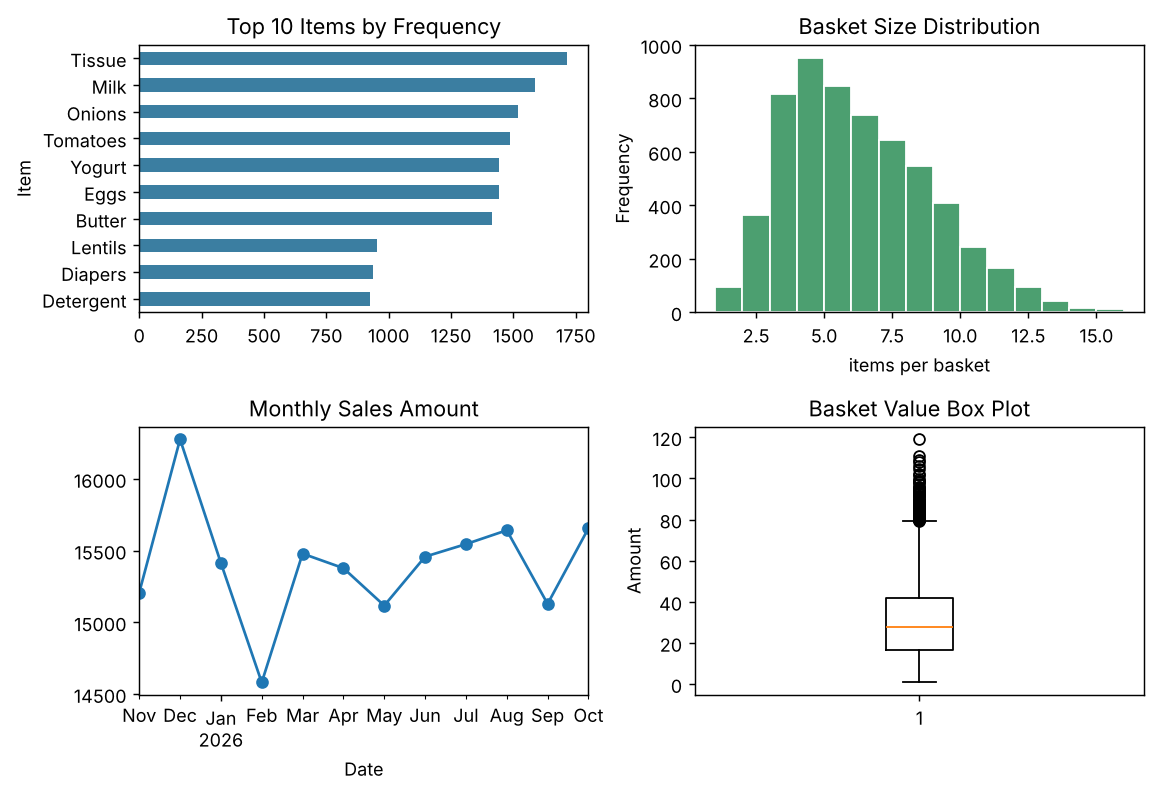

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/market_basket_transactions.csv").dropna(subset=["CustomerID"]).drop_duplicates()
df = df[df["Quantity"] > 0]
df["Date"] = pd.to_datetime(df["Date"]); df["Amount"] = df["Quantity"] * df["UnitPrice"]
size = df.groupby("TransactionID")["Item"].nunique()
fig, ax = plt.subplots(2, 2, figsize=(9, 6.2))
df["Item"].value_counts().head(10).sort_values().plot.barh(ax=ax[0, 0], color="#3B7EA1")    # top items
ax[0, 0].set_title("Top 10 Items by Frequency")
ax[0, 1].hist(size, bins=range(1, 17), color="#4C9F70", edgecolor="white")                    # histogram
ax[0, 1].set(title="Basket Size Distribution", xlabel="items per basket", ylabel="Frequency")
df.groupby(df["Date"].dt.to_period("M"))["Amount"].sum().plot(ax=ax[1, 0], marker="o")       # trend
ax[1, 0].set_title("Monthly Sales Amount")
ax[1, 1].boxplot(df.groupby("TransactionID")["Amount"].sum())                                 # box plot
ax[1, 1].set(title="Basket Value Box Plot", ylabel="Amount")
plt.tight_layout(); plt.show()
print("Average basket size:", round(size.mean(), 2), "items | median:", size.median())
print("Average basket value:", round(df.groupby("TransactionID")["Amount"].sum().mean(), 2))
print("\nTop 5 items:\n", df["Item"].value_counts().head(5).to_string())

## Lab 4: Frequent Pattern Mining using Apriori

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules

df = pd.read_csv("data/market_basket_transactions.csv").dropna(subset=["CustomerID"]).drop_duplicates()
df = df[df["Quantity"] > 0]
basket = pd.crosstab(df["TransactionID"], df["Item"]).astype(bool)   # one-hot basket matrix

frequent_itemsets = apriori(basket, min_support=0.03, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.4)
rules = rules[rules["lift"] > 1.5]
fmt = lambda s: ", ".join(sorted(s))
show = rules.assign(antecedents=rules["antecedents"].apply(fmt), consequents=rules["consequents"].apply(fmt))
print("Baskets:", basket.shape[0], "| Items:", basket.shape[1])
print("Frequent itemsets:", len(frequent_itemsets), "| Rules (conf>=0.4, lift>1.5):", len(rules))
print(show[["antecedents", "consequents", "support", "confidence", "lift"]]
      .sort_values("lift", ascending=False).head(8).round(3).to_string(index=False))

plt.figure(figsize=(5.2, 3.2))
plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=18)
plt.colorbar(label="lift"); plt.xlabel("Support"); plt.ylabel("Confidence"); plt.title("Association Rules")
plt.tight_layout(); plt.show()

## Lab 5: Frequent Pattern Mining using FP-Growth

In [ ]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

df = pd.read_csv("data/market_basket_transactions.csv").dropna(subset=["CustomerID"]).drop_duplicates()
df = df[df["Quantity"] > 0]
basket = pd.crosstab(df["TransactionID"], df["Item"]).astype(bool)

fp = fpgrowth(basket, min_support=0.03, use_colnames=True)
ap = apriori(basket, min_support=0.03, use_colnames=True)
print("FP-Growth itemsets:", len(fp), "| Apriori itemsets:", len(ap), "| identical:", set(fp["itemsets"]) == set(ap["itemsets"]))
print("Itemsets by size:", fp["itemsets"].apply(len).value_counts().sort_index().to_dict())

rules = association_rules(fp, metric="confidence", min_threshold=0.5)
rules = rules[rules["antecedents"].apply(len) == 1]          # single-item "if X then Y" rules
fmt = lambda s: ", ".join(sorted(s))
rules["antecedents"] = rules["antecedents"].apply(fmt); rules["consequents"] = rules["consequents"].apply(fmt)
print("\nTop single-item rules by confidence (>= 0.5):")
print(rules[["antecedents", "consequents", "support", "confidence", "lift"]]
      .sort_values("confidence", ascending=False).head(6).round(3).to_string(index=False))

## Lab 6: Classification using Decision Tree

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("data/market_basket_transactions.csv").dropna(subset=["CustomerID"]).drop_duplicates()
df = df[df["Quantity"] > 0]
basket = pd.crosstab(df["TransactionID"], df["Item"]).astype(int)

# Cross-selling task: will the basket contain Butter, given the other items?
y = basket["Butter"]
X = basket.drop(columns="Butter")
print("Butter appears in", round(y.mean() * 100, 1), "% of baskets")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {}
for crit in ["gini", "entropy"]:
    m = DecisionTreeClassifier(criterion=crit, max_depth=5, random_state=42).fit(X_train, y_train)
    models[crit] = m
    print(f"{crit:8s} -> accuracy {accuracy_score(y_test, m.predict(X_test))*100:.2f}%")
best = max(models, key=lambda c: accuracy_score(y_test, models[c].predict(X_test)))
pred = models[best].predict(X_test)
print(f"\nClassification Report ({best} tree):")
print(classification_report(y_test, pred, target_names=["No Butter", "Butter"]))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
print("Top splitting items:", pd.Series(models[best].feature_importances_, index=X.columns).nlargest(3).round(3).to_dict())

Butter appears in 23.6 % of baskets
gini     -> accuracy 87.42%
entropy  -> accuracy 87.83%

Classification Report (entropy tree):
              precision    recall  f1-score   support

   No Butter       0.96      0.88      0.92       917
      Butter       0.69      0.87      0.77       283

    accuracy                           0.88      1200
   macro avg       0.82      0.87      0.84      1200
weighted avg       0.89      0.88      0.88      1200

Confusion Matrix:
 [[809 108]
 [ 38 245]]
Top splitting items: {'Eggs': 0.56, 'Cake': 0.144, 'Bread': 0.135}


## Lab 7: Classification using Naive Bayes

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("data/market_basket_transactions.csv").dropna(subset=["CustomerID"]).drop_duplicates()
df = df[df["Quantity"] > 0]
basket = pd.crosstab(df["TransactionID"], df["Item"]).astype(int)
y, X = basket["Butter"], basket.drop(columns="Butter")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

gnb = GaussianNB().fit(X_train, y_train)
bnb = BernoulliNB().fit(X_train, y_train)          # suited to yes/no (binary) item features
print(f"GaussianNB accuracy : {accuracy_score(y_test, gnb.predict(X_test))*100:.2f}%")
print(f"BernoulliNB accuracy: {accuracy_score(y_test, bnb.predict(X_test))*100:.2f}%")
pred = bnb.predict(X_test)
print("\nClassification Report (BernoulliNB):")
print(classification_report(y_test, pred, target_names=["No Butter", "Butter"]))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred))

GaussianNB accuracy : 87.08%
BernoulliNB accuracy: 87.83%

Classification Report (BernoulliNB):
              precision    recall  f1-score   support

   No Butter       0.95      0.89      0.92       917
      Butter       0.70      0.83      0.76       283

    accuracy                           0.88      1200
   macro avg       0.83      0.86      0.84      1200
weighted avg       0.89      0.88      0.88      1200

Confusion Matrix:
 [[818  99]
 [ 47 236]]


## Lab 8: Classification using Support Vector Machine

linear kernel accuracy: 87.08%
rbf    kernel accuracy: 88.42%
Best parameters: {'C': 1, 'gamma': 0.1} | CV accuracy: 0.8779
Tuned SVM test accuracy: 87.75%
              precision    recall  f1-score   support

   No Butter       0.95      0.88      0.92       917
      Butter       0.69      0.86      0.77       283

    accuracy                           0.88      1200
   macro avg       0.82      0.87      0.84      1200
weighted avg       0.89      0.88      0.88      1200


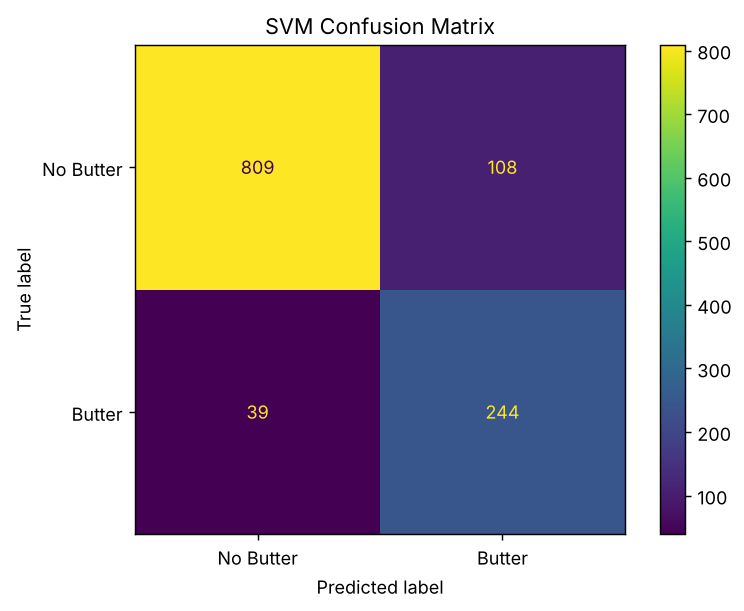

In [6]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv("data/market_basket_transactions.csv").dropna(subset=["CustomerID"]).drop_duplicates()
df = df[df["Quantity"] > 0]
basket = pd.crosstab(df["TransactionID"], df["Item"]).astype(int)
y, X = basket["Butter"], basket.drop(columns="Butter")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

for k in ["linear", "rbf"]:
    p = SVC(kernel=k).fit(X_train, y_train)
    print(f"{k:6s} kernel accuracy: {accuracy_score(y_test, p.predict(X_test))*100:.2f}%")
grid = GridSearchCV(SVC(kernel="rbf"), {"C": [1, 10], "gamma": ["scale", 0.1]}, cv=3).fit(X_train, y_train)
print("Best parameters:", grid.best_params_, "| CV accuracy:", round(grid.best_score_, 4))
pred = grid.predict(X_test)
print(f"Tuned SVM test accuracy: {accuracy_score(y_test, pred)*100:.2f}%")
print(classification_report(y_test, pred, target_names=["No Butter", "Butter"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No Butter", "Butter"]).plot()
plt.title("SVM Confusion Matrix"); plt.tight_layout(); plt.show()

## Lab 9: K-Means Clustering

Customers: 785 | silhouette (k=2..5): [0.44, 0.442, 0.411, 0.391]

Segment profile (mean RFM):
         customers  Recency  Frequency  Monetary
Segment                                         
0              346     43.3        4.8     140.3
1              236     31.7       10.8     339.4
2               71     15.6       18.8     605.6
3              132    177.1        3.3     100.3


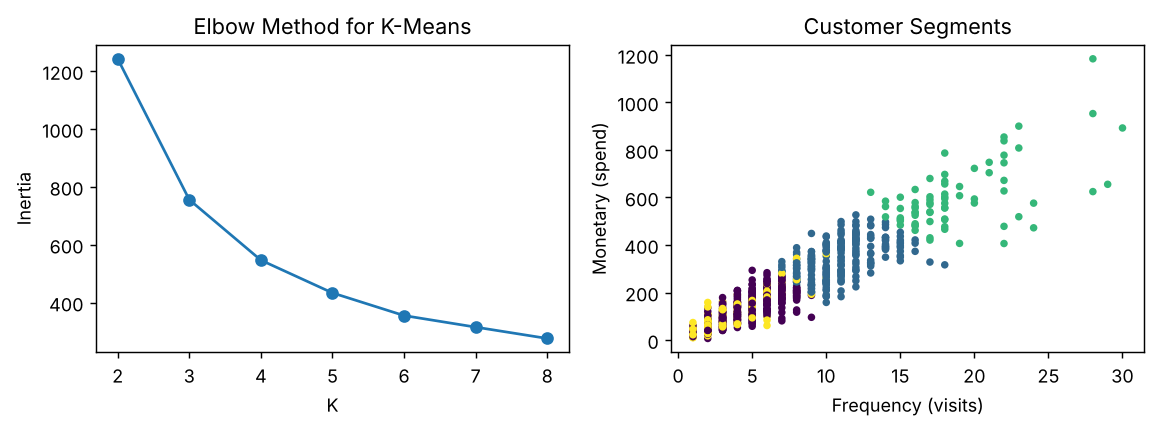

In [7]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv("data/market_basket_transactions.csv").dropna(subset=["CustomerID"]).drop_duplicates()
df = df[df["Quantity"] > 0]
df["Date"] = pd.to_datetime(df["Date"]); df["Amount"] = df["Quantity"] * df["UnitPrice"]
today = pd.Timestamp("2026-11-01")
rfm = df.groupby("CustomerID").agg(Recency=("Date", lambda d: (today - d.max()).days),
                                   Frequency=("TransactionID", "nunique"), Monetary=("Amount", "sum"))
X = StandardScaler().fit_transform(rfm)

inertia, sil = [], []
for k in range(2, 9):                                     # elbow method
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(m.inertia_); sil.append(silhouette_score(X, m.labels_))
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X)
rfm["Segment"] = km.labels_
print("Customers:", len(rfm), "| silhouette (k=2..5):", [round(s, 3) for s in sil[:4]])
print("\nSegment profile (mean RFM):")
print(rfm.groupby("Segment").agg(customers=("Monetary", "size"), Recency=("Recency", "mean"),
      Frequency=("Frequency", "mean"), Monetary=("Monetary", "mean")).round(1))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(range(2, 9), inertia, "o-"); ax[0].set(title="Elbow Method for K-Means", xlabel="K", ylabel="Inertia")
ax[1].scatter(rfm["Frequency"], rfm["Monetary"], c=km.labels_, s=10)
ax[1].set(title="Customer Segments", xlabel="Frequency (visits)", ylabel="Monetary (spend)")
plt.tight_layout(); plt.show()

## Lab 10: Hierarchical Clustering and DBSCAN

Hierarchical cluster sizes: [399 170 146  70] | silhouette: 0.3453
DBSCAN clusters: 2 | noise points: 33
DBSCAN silhouette (non-noise): 0.5069
Mean spend: noise 512.6 vs clustered 223.4


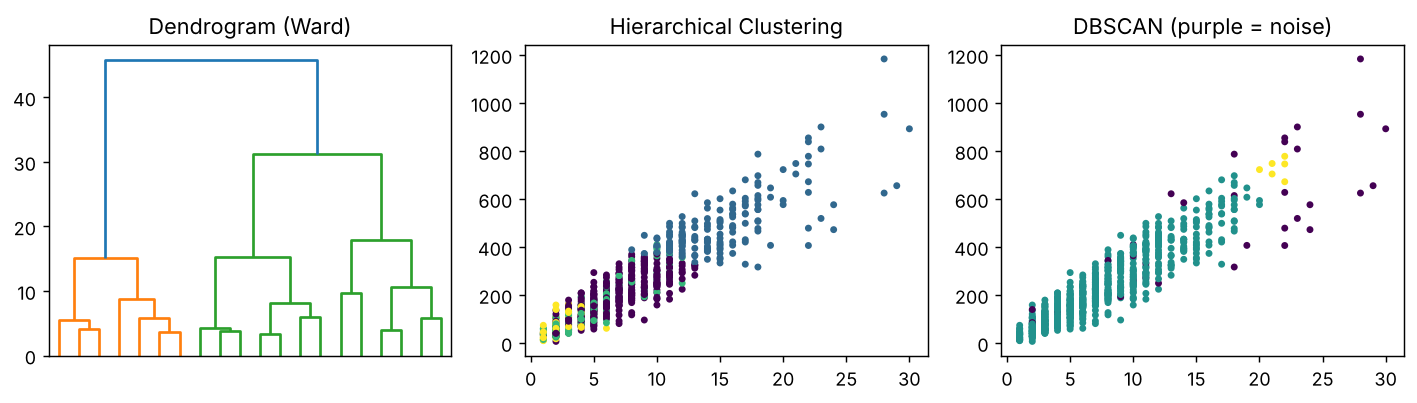

In [8]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

df = pd.read_csv("data/market_basket_transactions.csv").dropna(subset=["CustomerID"]).drop_duplicates()
df = df[df["Quantity"] > 0]
df["Date"] = pd.to_datetime(df["Date"]); df["Amount"] = df["Quantity"] * df["UnitPrice"]
rfm = df.groupby("CustomerID").agg(Recency=("Date", lambda d: (pd.Timestamp("2026-11-01") - d.max()).days),
                                   Frequency=("TransactionID", "nunique"), Monetary=("Amount", "sum"))
X = StandardScaler().fit_transform(rfm)

hier = AgglomerativeClustering(n_clusters=4).fit_predict(X)
print("Hierarchical cluster sizes:", np.bincount(hier), "| silhouette:", round(silhouette_score(X, hier), 4))
db = DBSCAN(eps=0.4, min_samples=5).fit_predict(X)
mask = db != -1
print("DBSCAN clusters:", len(set(db) - {-1}), "| noise points:", int((~mask).sum()))
print("DBSCAN silhouette (non-noise):", round(silhouette_score(X[mask], db[mask]), 4))
print("Mean spend: noise", round(rfm[~mask]["Monetary"].mean(), 1), "vs clustered", round(rfm[mask]["Monetary"].mean(), 1))

fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
dendrogram(linkage(X, "ward"), truncate_mode="lastp", p=20, no_labels=True, ax=ax[0]); ax[0].set_title("Dendrogram (Ward)")
ax[1].scatter(rfm["Frequency"], rfm["Monetary"], c=hier, s=8); ax[1].set_title("Hierarchical Clustering")
ax[2].scatter(rfm["Frequency"], rfm["Monetary"], c=db, s=8); ax[2].set_title("DBSCAN (purple = noise)")
plt.tight_layout(); plt.show()

## Lab 11: Outlier Detection and Ensemble Methods

In [9]:
import pandas as pd, numpy as np
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv("data/market_basket_transactions.csv").dropna(subset=["CustomerID"]).drop_duplicates()
df = df[df["Quantity"] > 0]
df["Amount"] = df["Quantity"] * df["UnitPrice"]
tx = df.groupby("TransactionID").agg(Items=("Item", "nunique"), Amount=("Amount", "sum"))

z = np.abs((tx - tx.mean()) / tx.std())
print("Z-Score outlier baskets (|z|>3):", int((z > 3).any(axis=1).sum()))
q1, q3 = tx.quantile(.25), tx.quantile(.75); iqr = q3 - q1
print("IQR outlier baskets            :", int(((tx < q1 - 1.5*iqr) | (tx > q3 + 1.5*iqr)).any(axis=1).sum()))
iso = IsolationForest(contamination=0.01, random_state=42).fit_predict(tx)
print("Isolation Forest outliers (1%) :", int((iso == -1).sum()), "| their mean amount:", round(tx[iso == -1]["Amount"].mean(), 1))

basket = pd.crosstab(df["TransactionID"], df["Item"]).astype(int)       # predict basket value from items
X_train, X_test, y_train, y_test = train_test_split(basket, tx["Amount"].loc[basket.index], test_size=0.2, random_state=42)
rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)
pred = rf.predict(X_test)
print(f"\nRandom Forest  R2: {r2_score(y_test, pred):.4f} | MSE: {mean_squared_error(y_test, pred):.4f}")
print("\nTop feature importances:")
print(pd.Series(rf.feature_importances_, index=basket.columns).nlargest(5).round(4))

Z-Score outlier baskets (|z|>3): 72
IQR outlier baskets            : 98
Isolation Forest outliers (1%) : 60 | their mean amount: 75.7

Random Forest  R2: 0.6789 | MSE: 99.8716

Top feature importances:
Item
Diapers    0.1070
Chicken    0.0987
Beef       0.0970
Fish       0.0915
Coffee     0.0756
dtype: float64


## Lab 12: End-to-End Mini Project: Market Basket Recommender

In [ ]:
import pandas as pd, numpy as np, pickle
from sklearn.model_selection import train_test_split
from mlxtend.frequent_patterns import fpgrowth, association_rules

df = pd.read_csv("data/market_basket_transactions.csv").dropna(subset=["CustomerID"]).drop_duplicates()
df = df[df["Quantity"] > 0]
basket = pd.crosstab(df["TransactionID"], df["Item"]).astype(bool)
train, test = train_test_split(basket, test_size=0.2, random_state=42)
print("Training baskets:", len(train), "| Testing baskets:", len(test))

fp = fpgrowth(train, min_support=0.02, use_colnames=True)
rules = association_rules(fp, metric="confidence", min_threshold=0.3)
rules = rules[rules["lift"] > 1.2]
print("Frequent itemsets:", len(fp), "| Usable rules:", len(rules))

def recommend(items, k=3):
    items = set(items); score = {}
    for a, c, conf in zip(rules["antecedents"], rules["consequents"], rules["confidence"]):
        if a <= items:
            for x in c - items: score[x] = max(score.get(x, 0), conf)
    return sorted(score, key=score.get, reverse=True)[:k]

popular = train.mean().sort_values(ascending=False).index.tolist()
rng, hits, base, n = np.random.default_rng(42), 0, 0, 0
for _, row in test.iterrows():
    its = list(row.index[row])
    if len(its) < 3: continue
    hide = rng.choice(its); rest = [i for i in its if i != hide]; n += 1
    hits += hide in recommend(rest); base += hide in [p for p in popular if p not in rest][:3]
print(f"Hit-rate@3 recommender: {hits/n:.3f} | popularity baseline: {base/n:.3f} ({n} test baskets)")
print("Example -> basket ['Bread', 'Butter'] suggests:", recommend(["Bread", "Butter"]))
print("Example -> basket ['Diapers'] suggests:", recommend(["Diapers"]))
pickle.dump(rules, open("market_basket_rules.pkl", "wb"))
print("Rules saved as: market_basket_rules.pkl")

### Interactive dashboard (Google Colab / Jupyter)
Tick products in the multi-select box (Ctrl/Cmd-click for several) — the bar chart of recommended products updates instantly. Run this cell after Lab 12.

In [ ]:
import ipywidgets as widgets, matplotlib.pyplot as plt
def show_recommendations(items, k=5):
    items = set(items); best = {}
    for a, c, conf in zip(rules["antecedents"], rules["consequents"], rules["confidence"]):
        if a <= items:
            for x in c - items: best[x] = max(best.get(x, 0), conf)
    top = sorted(best.items(), key=lambda kv: kv[1], reverse=True)[:k]
    plt.figure(figsize=(5.5, 2.5))
    plt.barh([t[0] for t in top][::-1], [t[1] for t in top][::-1], color="#3B7EA1")
    plt.xlim(0, 1); plt.xlabel("Confidence"); plt.title("Basket: " + ", ".join(sorted(items)))
    plt.show()
picker = widgets.SelectMultiple(options=sorted(basket.columns), value=["Bread", "Butter"], description="Basket", rows=8)
out = widgets.interactive_output(lambda items: show_recommendations(items), {"items": picker})
display(picker, out)          # tick items -> recommendations update instantly